# Подготовка

## Импорты

In [93]:
from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd

from src.dataset import DatasetStore
from src.runner import ExperimentRunner
from src.pipeline import Pipeline
from src.preprocessors import *
from src.models import *
from src.validators import *

In [94]:
import warnings
warnings.filterwarnings('ignore')

## Загрузка данных

In [95]:
df, schema = DatasetStore.load(
    "data/processed/dataset.csv",
    "data/processed/dataset.schema.json",
    include_missing=False,
)
feature_info = DatasetStore.get_feature_info(
    schema,
    include_missing=False,
)

In [96]:
columns = ['bled cut', 'albumin']
for col in columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [97]:
df["diagnosis"] = df["diagnosis"].replace(6, 5)

y = LabelEncoder().fit_transform(df['diagnosis'].values)
X = df.drop(columns=['diagnosis'])

class_labels = [0, 1]

In [98]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [99]:
top_15_features = [
    "meteorism",
    "LS/cen gid",
    "rigid of abdomi",
    "Ur",
    "LS steat",
    "glu",
    "intensiv",
    "pain of adbomin",
    "Ht",
    "pain",
    "amilase",
    "s. peritonit",
    "icterus",
    "mramor cut",
    "bil",
]
X_top15 = X_test[top_15_features]

# Сравнение

In [100]:
model1 = ExperimentRunner.load_pipeline('_results/RandomForest/pipeline.joblib')
model2 = ExperimentRunner.load_pipeline('_results/RandomForestTop15/pipeline.joblib')

In [101]:
y_pred1 = model1.predict(X_test)
y_pred2 = model2.predict(X_top15)

In [102]:
y_pred_proba1 = model1.predict_proba(X_test)
y_pred_proba2 = model2.predict_proba(X_top15)

## МакНемар

In [103]:
from mlxtend.evaluate import mcnemar_table, mcnemar

table = mcnemar_table(y_test, y_pred1, y_pred2)
table

array([[70,  1],
       [ 2,  6]])

In [104]:
result = mcnemar(table, exact=True)
result

(None, np.float64(1.0))

## Доверительный интервал разности

In [105]:
from sklearn.metrics import matthews_corrcoef
from sklearn.utils import resample

In [106]:
differences = []
n_iterations = 2000
indices = np.arange(len(y_test))

for _ in range(n_iterations):
    # Генерируем случайные индексы с возвращением
    boot_idx = resample(indices)
    
    # Считаем метрику для обеих моделей на бутстреп-выборке
    f1_m1 = matthews_corrcoef(y_test[boot_idx], y_pred1[boot_idx])
    f1_m2 = matthews_corrcoef(y_test[boot_idx], y_pred2[boot_idx])
    
    differences.append(f1_m1 - f1_m2)

# Находим 95% доверительный интервал (от 2.5% до 97.5% перцентиля)
ci_lower = np.percentile(differences, 2.5)
ci_upper = np.percentile(differences, 97.5)

In [107]:
print(f"95% Bootstrap CI для разности matthews_corrcoef: [{ci_lower:.4f}, {ci_upper:.4f}]")
print("Разница значима (интервал не содержит 0)" if ci_lower > 0 or ci_upper < 0 else "Разница НЕ значима")

95% Bootstrap CI для разности matthews_corrcoef: [-0.1259, 0.0596]
Разница НЕ значима


## Ошибки

In [108]:
df['set'] = 'test'
df.loc[X_train.index, 'set'] = 'train'

In [109]:
df_test = df[df["set"] == "test"]
df_test["model1"] = np.where(y_pred1 == 0, 1, 5)
df_test["model2"] = np.where(y_pred2 == 0, 1, 5)

In [110]:
df_test[df_test["model1"] != df_test["diagnosis"]].index

Index([  0,   3,  15,  22,  25,  33,  39,  42,  45,  56,  73,  76,  77,  78,
        82,  84,  93, 108, 110, 114, 116, 124, 140, 141, 150, 155, 157, 173,
       195, 203, 233, 246, 247, 253, 255, 268, 274, 275, 287, 289, 305, 345,
       361, 362, 369, 374, 383, 387],
      dtype='int64')

In [111]:
df_test[df_test["model2"] != df_test["diagnosis"]].index

Index([  0,   3,  15,  22,  25,  33,  39,  42,  45,  56,  73,  76,  78,  82,
        84,  90,  93, 108, 110, 114, 116, 124, 140, 141, 150, 155, 157, 173,
       195, 203, 233, 246, 247, 253, 255, 268, 274, 275, 287, 289, 345, 361,
       362, 369, 374, 383, 387],
      dtype='int64')

## Графики ROC и PR

In [112]:
from pathlib import Path
import json

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

In [113]:
def collect_curves(json_paths):
    """Читает список JSON-файлов и достаёт данные для ROC и PR кривых."""
    roc_items, pr_items = [], []

    for p in json_paths:
        p = Path(p)
        full_path = "_analys" / p / "detailed.json"
        with open(full_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        label = p.stem  
        roc = data.get("holdout", {}).get("roc_curves", {}).get("binary")
        pr = data.get("holdout", {}).get("pr_curves", {}).get("binary")

        if roc is not None:
            roc_items.append((label, roc))
        if pr is not None:
            pr_items.append((label, pr))

    return roc_items, pr_items

In [114]:
json_files = [
    "RandomForest",
    "RandomForestTop5",
    "RandomForestTop10",
    "RandomForestTop15",
]
roc_items, pr_items = collect_curves(json_files)

FileNotFoundError: [Errno 2] No such file or directory: '_analys\\RandomForest\\detailed.json'

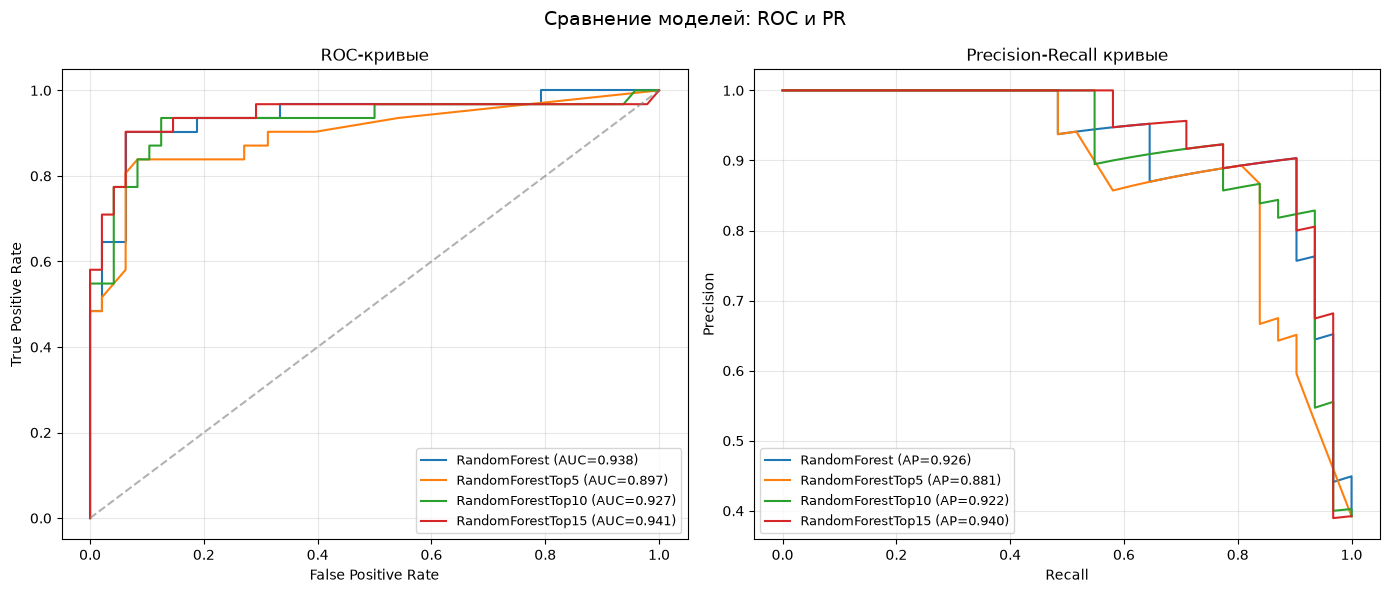

In [ ]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 6))

# ---------- ROC ----------
for label, roc in roc_items:
    auc = roc.get("auc")
    name = f"{label} (AUC={auc:.3f})" if auc is not None else label
    ax_roc.plot(roc["fpr"], roc["tpr"], label=name)

ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", alpha=0.6)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC-кривые")
ax_roc.legend(loc="lower right", fontsize=9)
ax_roc.grid(True, alpha=0.3)

# ---------- PR ----------
for label, pr in pr_items:
    ap = pr.get("average_precision")
    name = f"{label} (AP={ap:.3f})" if ap is not None else label
    ax_pr.plot(pr["recall"], pr["precision"], label=name)

ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.set_title("Precision-Recall кривые")
ax_pr.legend(loc="lower left", fontsize=9)
ax_pr.grid(True, alpha=0.3)

fig.suptitle("Сравнение моделей: ROC и PR", fontsize=14)
fig.tight_layout()

plt.show()